In [50]:
import pandas as pd

In [51]:
data = "data.csv"
df = pd.read_csv(data)

In [52]:
df.shape

(11914, 16)

In [53]:
df.sample(5)

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
2070,Mercedes-Benz,C-Class,2015,premium unleaded (required),201.0,4.0,AUTOMATIC,rear wheel drive,2.0,Luxury,Compact,Coupe,31,22,617,39400
8606,Kia,Rondo,2009,regular unleaded,175.0,4.0,AUTOMATIC,front wheel drive,4.0,NaN,Compact,Wagon,27,20,1720,17495
2394,Volkswagen,CC,2015,premium unleaded (recommended),200.0,4.0,AUTOMATED_MANUAL,front wheel drive,4.0,Performance,Midsize,Sedan,31,22,873,34095
506,BMW,5 Series Gran Turismo,2015,premium unleaded (required),445.0,8.0,AUTOMATIC,all wheel drive,4.0,"Hatchback,Luxury,Performance",Large,4dr Hatchback,24,16,3916,71400
5817,Chevrolet,Impala Limited,2015,flex-fuel (unleaded/E85),300.0,6.0,AUTOMATIC,front wheel drive,4.0,Flex Fuel,Large,Sedan,30,18,1385,26840


In [54]:
df.columns = df.columns.str.lower().str.replace(" ", "_")

In [55]:
df.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'msrp'],
      dtype='str')

In [56]:
df.dtypes

make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors      float64
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
msrp                   int64
dtype: object

In [57]:
strings_cols = list(df.dtypes[df.dtypes == "str"].index)

In [58]:
strings_cols

['make',
 'model',
 'engine_fuel_type',
 'transmission_type',
 'driven_wheels',
 'market_category',
 'vehicle_size',
 'vehicle_style']

In [59]:
for col in strings_cols:
    df[col] = df[col].str.lower().str.replace(' ', '_')

In [60]:
df.sample(5)

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
3048,honda,cr-v,2015,regular_unleaded,185.0,4.0,automatic,front_wheel_drive,4.0,crossover,compact,4dr_suv,34,27,2202,23445
63,audi,200,1991,regular_unleaded,162.0,5.0,automatic,front_wheel_drive,4.0,luxury,midsize,sedan,20,16,3105,2000
4939,ford,freestyle,2006,regular_unleaded,203.0,6.0,automatic,front_wheel_drive,4.0,crossover,large,wagon,25,18,5657,28530
11452,subaru,wrx,2015,premium_unleaded_(recommended),268.0,4.0,automatic,all_wheel_drive,4.0,performance,compact,sedan,25,19,640,31195
7266,nissan,nv200,2016,regular_unleaded,131.0,4.0,automatic,front_wheel_drive,4.0,NaN,compact,cargo_minivan,26,24,2009,21760


# eda

In [61]:
for col in df.columns[8:]:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()

number_of_doors
[ 2.  4.  3. nan]
3

market_category
<StringArray>
['factory_tuner,luxury,high-performance',
                    'luxury,performance',
               'luxury,high-performance',
                                'luxury',
                           'performance']
Length: 5, dtype: str
71

vehicle_size
<StringArray>
['compact', 'midsize', 'large']
Length: 3, dtype: str
3

vehicle_style
<StringArray>
['coupe', 'convertible', 'sedan', 'wagon', '4dr_hatchback']
Length: 5, dtype: str
16

highway_mpg
[26 28 27 25 24]
59

city_mpg
[19 20 18 17 16]
69

popularity
[3916 3105  819  617 1013]
48

msrp
[46135 40650 36350 29450 34500]
6049



In [62]:
import seaborn as sns

<Axes: xlabel='msrp', ylabel='Count'>

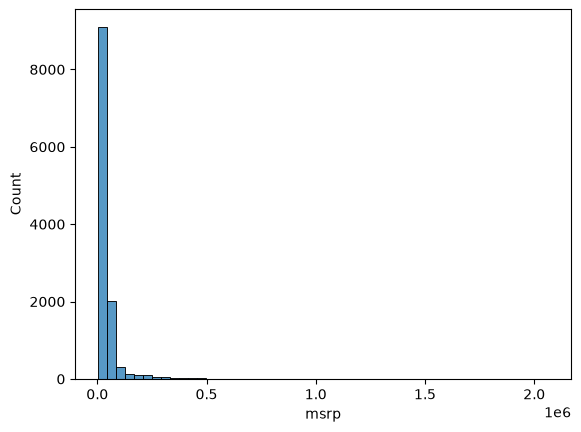

In [63]:
sns.histplot(df["msrp"], bins=50)

<Axes: xlabel='msrp', ylabel='Count'>

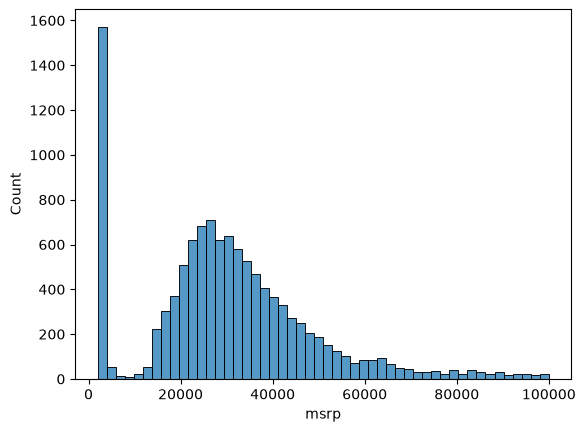

In [64]:
sns.histplot(df.msrp[df.msrp < 100000], bins=50)

In [65]:
import numpy as np

In [66]:
price_logs = np.log1p(df["msrp"])

<Axes: xlabel='msrp', ylabel='Count'>

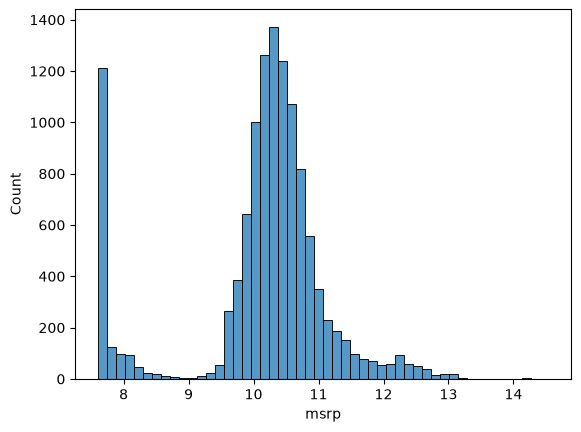

In [67]:
sns.histplot(price_logs, bins=50)

In [68]:
df.isnull().sum()

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

# split

In [69]:
n = len(df)

n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

In [70]:
n, n_val, n_test, n_train

(11914, 2382, 2382, 7150)

In [71]:
np.random.seed(2)

idx = np.arange(n)
np.random.shuffle(idx)

In [72]:
df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train : n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val :]]

In [73]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [74]:
y_train = np.log1p(df_train.msrp.values)
y_val = np.log1p(df_val.msrp.values)
y_test = np.log1p(df_test.msrp.values)

In [75]:
del df_train["msrp"]
del df_val["msrp"]
del df_test["msrp"]

In [76]:
y_train

array([ 9.57574708,  9.887663  ,  9.89323518, ..., 10.45380308,
       12.62248099, 10.54061978], shape=(7150,))

# Model

In [77]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

# base model

In [78]:
df_train.dtypes[df_train.dtypes != "str"]

year                  int64
engine_hp           float64
engine_cylinders    float64
number_of_doors     float64
highway_mpg           int64
city_mpg              int64
popularity            int64
dtype: object

In [79]:
base = ["engine_hp", "engine_cylinders", "highway_mpg", "city_mpg", "popularity"]

In [80]:
df_train[base].isnull().sum()

engine_hp           40
engine_cylinders    14
highway_mpg          0
city_mpg             0
popularity           0
dtype: int64

In [81]:
X_train = df_train[base].fillna(0).values

In [82]:
w0, w = train_linear_regression(X_train, y_train)

In [83]:
w

array([ 9.70589522e-03, -1.59103494e-01,  1.43792133e-02,  1.49441072e-02,
       -9.06908672e-06])

In [84]:
y_pred = w0 + X_train.dot(w)

<Axes: ylabel='Count'>

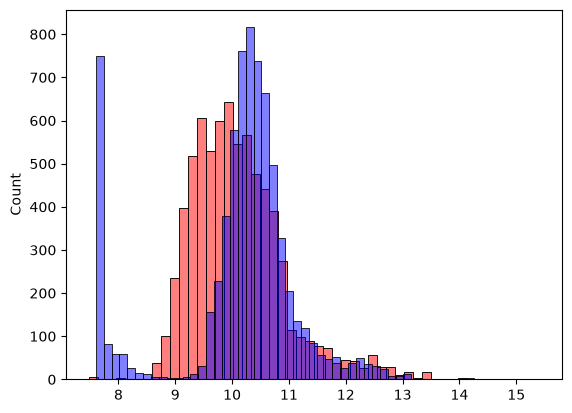

In [85]:
sns.histplot(y_pred, color="red", alpha=0.5, bins=50)
sns.histplot(y_train, color="blue", alpha=0.5, bins=50)

In [86]:
np.expm1(y_pred)

array([ 14014.62180872,  11935.30375066,  15865.69570384, ...,
        29857.6585652 , 159194.99512196,  21995.33467203], shape=(7150,))

# rmse

In [87]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

# validar 

In [88]:
def prepare_X(df):
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [89]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.761653099130156)

# feature engineering

In [90]:
def prepare_X(df):
    df["age"] = 2017 - df.year
    features = base + ["age"]

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [91]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.5172055461058299)

<Axes: ylabel='Count'>

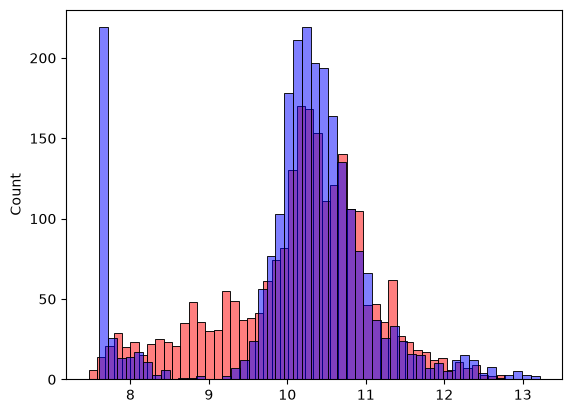

In [92]:
sns.histplot(y_pred, label="prediction", color="red", alpha=0.5, bins=50)
sns.histplot(y_val, label="target", color="blue", alpha=0.5, bins=50)

In [93]:
strings_cols

['make',
 'model',
 'engine_fuel_type',
 'transmission_type',
 'driven_wheels',
 'market_category',
 'vehicle_size',
 'vehicle_style']

In [94]:
df[df.columns[df.dtypes == "float64"]]

,engine_hp,engine_cylinders,number_of_doors
0,335.0,6.0,2.0
1,300.0,6.0,2.0
2,300.0,6.0,2.0
3,230.0,6.0,2.0
4,230.0,6.0,2.0
...,...,...,...
11909,300.0,6.0,4.0
11910,300.0,6.0,4.0
11911,300.0,6.0,4.0
11912,300.0,6.0,4.0


# variables categoricas

In [95]:
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    df["age"] = 2017 - df.year
    features.append("age")

    for v in [2, 3, 4]:
        df["num_doors_%s" % v] = (df.number_of_doors == v).astype("int")
        features.append("num_doors_%s" % v)

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [96]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.515799564150169)

In [97]:
df.make.value_counts().head()
makes = list(df.make.value_counts().head().index)
for v in makes:
    df["make_%s" % v] = (df.make == v).astype("int")
    features.append("make_%s" % v)

NameError: name 'features' is not defined

In [104]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

# regularizacion

In [99]:
for r in [0.0, 0.00001, 0.0001, 0.001, 0.1, 1, 10]:
    X_train = prepare_X(df_train)
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)

    X_val = prepare_X(df_val)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)

    print(r, w0, score)

0.0 10.659085118454128 0.515799564150169
1e-05 10.659056886829932 0.5157995707256945
0.0001 10.658802820463801 0.5157996299071498
0.001 10.65626394292027 0.5158002219471609
0.1 10.395476266089734 0.5158674745473458
1 9.001523583176505 0.5165272172025679
10 6.881162539373185 0.5244272457204655


# Final

In [100]:
df_full_train = pd.concat([df_train, df_val])

In [101]:
df_full_train = df_full_train.reset_index(drop=True)

In [102]:
X_full_train = prepare_X(df_full_train)

In [106]:
y_full_train = np.concatenate([y_train, y_val])

In [107]:
w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)

In [108]:
X_test = prepare_X(df_test)
y_pred = w0 + X_test.dot(w)
score = rmse(y_test, y_pred)
score

np.float64(0.5135836841151029)

In [109]:
car = df_test.iloc[20].to_dict()
car

{'make': 'toyota',
 'model': 'sienna',
 'year': 2015,
 'engine_fuel_type': 'regular_unleaded',
 'engine_hp': 266.0,
 'engine_cylinders': 6.0,
 'transmission_type': 'automatic',
 'driven_wheels': 'front_wheel_drive',
 'number_of_doors': 4.0,
 'market_category': nan,
 'vehicle_size': 'large',
 'vehicle_style': 'passenger_minivan',
 'highway_mpg': 25,
 'city_mpg': 18,
 'popularity': 2031}

In [111]:
df_small = pd.DataFrame([car])
X_small = prepare_X(df_small)
X_small

array([[2.660e+02, 6.000e+00, 2.500e+01, 1.800e+01, 2.031e+03, 2.000e+00,
        0.000e+00, 0.000e+00, 1.000e+00]])

In [117]:
y_pred = w0 + X_small.dot(w)
y_pred = y_pred[0]
y_pred

np.float64(10.607733088835014)

In [113]:
np.expm1(y_pred)

np.float64(40445.406838391)

In [114]:
np.expm1(y_test[20])

np.float64(35000.00000000001)